In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
import scipy.sparse as sp
import anndata as ad
import gseapy as gp
from copy import deepcopy
import scanpy.external as sce
import pickle

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import chronopack as cp

In [2]:
import os
from pathlib import Path

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "k562-tnfa.hg38.rep"
NEGATIVE_CONTROL_PATH = Path('../inputs/k562_neg-ctrl_mtx-agg.pkl')

# The bulk K562 negative control (N706, ArrayExpress E-MTAB-15966) summed per time tag. If the pickle is missing,
# download N706's DGE table and rebuild it (written to a temporary file first, so a parallel run never reads half of it).
if not NEGATIVE_CONTROL_PATH.exists():
    n706 = Path('../inputs/N706_Bulk_K562_Control_600_Cells.aligned.sorted.merged.tagged.dge.time_tags.csv.gz')
    cp.io.download_arrayexpress_files('E-MTAB-15966', [n706])
    tmp = NEGATIVE_CONTROL_PATH.with_name(f'{NEGATIVE_CONTROL_PATH.name}.{os.getpid()}.tmp')
    cp.io.sum_dge_by_time_tag(n706).to_pickle(tmp)
    tmp.replace(NEGATIVE_CONTROL_PATH)

In [3]:
adata = sc.read_h5ad(EXP_DIR / 'output/adata_full.1e4-variant.chk1.h5ad')

cell_type_by_traj_cluster = {'0': 'K562_Immune', '1': 'K562_Erythroid'}
adata.obs['cell_type'] = adata.obs['traj_clusters'].apply(cell_type_by_traj_cluster.get)

In [4]:
adata.shape

(6857, 20036)

# Compute correlations

In [5]:
corr = cp.tl.identify_tag_bias_candidates(
    adata,
    NEGATIVE_CONTROL_PATH,
    method='spline',
    method_kwargs=dict(s=None, k=3),
    local_r_threshold=0.8,
    local_fraction_threshold=0.5,
)


In [6]:
corr = cp.tl.filter_tag_bias_candidates(
    corr,
    local_r_threshold=0.7,
    local_fraction_threshold=0.25,
    use_residual_only=True,
)

print("Tag-bias candidates:", int(corr["tag_bias_candidate"].sum()))

corr[
    [
        "pearson_r_residual",
        "residual_explained_total_fraction",
        "pearson_r_diff",
        "diff_residual_explained_fraction",
        "tag_bias_candidate_residual",
        "tag_bias_candidate_diff",
        "tag_bias_candidate",
    ]
].head(20)


Tag-bias candidates: 1025


,pearson_r_residual,residual_explained_total_fraction,pearson_r_diff,diff_residual_explained_fraction,tag_bias_candidate_residual,tag_bias_candidate_diff,tag_bias_candidate
gene,,,,,,,
LINC01206,1.000000,0.500097,1.000000,0.755222,True,True,True
ENSG00000279881,1.000000,0.500097,1.000000,0.755222,True,True,True
LINC02029,1.000000,0.499994,1.000000,0.674177,True,True,True
DDX25,1.000000,0.500095,1.000000,0.759077,True,True,True
PAK5,1.000000,0.499994,1.000000,0.674177,True,True,True
MAP6,1.000000,0.263736,1.000000,0.521177,True,True,True
ENSG00000305226,0.998625,0.498425,0.930697,0.806570,True,True,True
MT-RNR1,0.998284,0.498504,0.994238,0.675906,True,True,True
ENSG00000288845,0.985284,0.485618,0.996473,0.678848,True,True,True


In [7]:
excl_genes = cp.tl.tag_bias_exclusion_genes(corr)

In [8]:
adata = cp.io.filter_technical_genes(adata, exclude_genes=excl_genes)
adata = cp.io.filter_low_count_genes(adata, min_total_counts=10, counts_layer="counts")
adata

AnnData object with n_obs × n_vars = 6857 × 11866
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden', 'traj_clusters', 'terminal_fate_probs_traj_0', 'terminal_fate_probs_traj_1', 'fate_0', 'fate_1', 'fate_entropy', 'fate_maxprob', 'traj_clusters_mass_ret_cell', 'cell_type'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'chronopack', 'hvg', 'leiden', 'log1p', 'neighbors', 'ot_graph', 'pca', 'phase_colors', 'sample_colors', 'scrublet', 'terminal_cell_dist_idx_last', 'terminal_fate_probs_traj_fates', 'terminal_fate_probs_traj_names', 'time_group_colors', 'traj_clusters', 'traj_clusters_colors', 'traj_cl

In [9]:
adata.write_h5ad(EXP_DIR / 'output/adata_prefiltered.1e4-variant.fixed.h5ad')
pd.Series(list(excl_genes)).to_csv(EXP_DIR / 'output/exclude_time-tag-bias_genes.csv', index=False, )

In [10]:
low_count_removed = int((adata.var_names.isin(set(adata.var_names) - set(adata.var_names))).sum())
print(f"Genes retained after technical, time-tag-bias, and low-count filtering: {adata.n_vars}")
print(f"Low-count threshold applied before writing tradeSeq inputs: total counts >= 10")

Genes retained after technical, time-tag-bias, and low-count filtering: 11866
Low-count threshold applied before writing tradeSeq inputs: total counts >= 10


# Prepare input files for TradeSeq

`04_TradeSeqFits` (one lineage) reads the counts, cell times and library sizes. `04_TradeSeqFits.TwoLineage` also reads `cell_weights.csv`: each cell's soft membership of the two trajectory clusters (0: inflammatory-high, 1: erythroid-like), from how much of its transport mass stays in its own cluster.

In [11]:
memberships = cp.tl.trajectory_soft_memberships(adata, cluster_key="traj_clusters")
memberships.describe()

,0,1
count,6857.000000,6857.000000
mean,0.524263,0.475737
std,0.400943,0.400943
min,0.000000,0.000000
25%,0.071283,0.044619
50%,0.569704,0.430296
75%,0.955381,0.928717
max,1.000000,1.000000


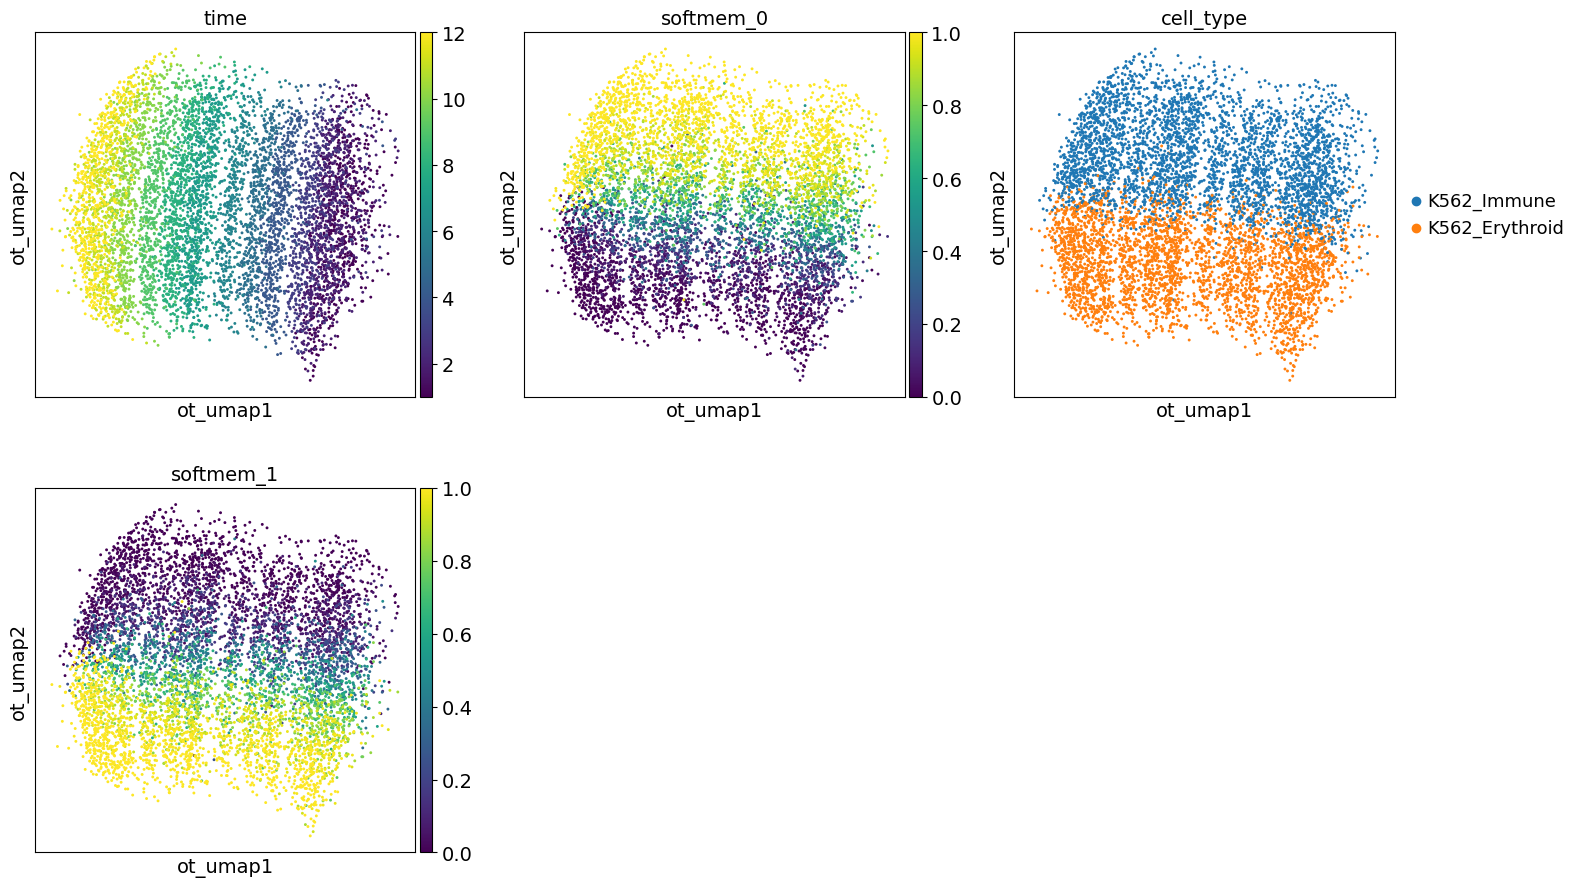

In [12]:
sc.pl.embedding(
    adata,
    basis='ot_umap',
    color=['time', 'softmem_0', 'cell_type', 'softmem_1'],
    ncols=3,
    cmap='viridis'
)

### Optional: pre-screen genes for time association

Off by default. Uncomment to write tradeSeq inputs for only the genes with some evidence of time association, which shortens `04_TradeSeqFits`. A least-squares F test of log-normalized expression on a cubic in time (3 df, like the 4-knot tradeSeq screen) keeps genes with p < 0.2. On these data that keeps about 41% of genes and 98% of the genes the full screen calls nominally significant (p < 0.05), including all of its top 500. The fits' q-values still count every screened gene. Not validated for the per-lineage tests of `04_TradeSeqFits.TwoLineage`, which reads the same inputs.

In [ ]:
# prescreen = cp.tl.prescreen_time_association(adata, df=3, p_threshold=0.2)
# print(f"Pre-screen keeps {int(prescreen['keep'].sum())} of {len(prescreen)} genes")
# adata = adata[:, prescreen["keep"]].copy()

In [13]:
cp.tl.fit_gene_dynamics(
    adata,
    output_dir=EXP_DIR / 'intmd/sc-K562-1e4_to_tradeSeq.fixed',
    cell_weights=memberships,
    prepare_inputs=True,
    run_backend=False,
)

GeneDynamicsResult(backend='tradeseq', key_added='gene_dynamics', metadata={'time_key': 'time', 'layer': 'counts', 'input_dir': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/scaling_20261020/data/k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq.fixed', 'n_points': 9, 'workers': 4, 'screen_nknots': 4, 'final_nknots': 8, 'p_threshold': 0.05, 'outputs': {'association': 'asso_df.1trajectory.nknots4.csv', 'significant': 'sig_df.1trajectory.nknots4.csv', 'sce_screen': 'sce_screen.1trajectory.nknots4.rds', 'sce': 'sce.1trajectory.nknots8.rds', 'screen_genes': 'screen_genes.1trajectory.nknots4.csv', 'session_info': 'sessionInfo.tradeSeqFits.txt'}, 'legacy_outputs': {'association': [], 'significant': [], 'sce_screen': [], 'sce': [], 'screen_genes': []}, 'lineage_weights': None, 'prepared_paths': {'counts': '/new-stg/home/alex/tmp/ChronoPack/verification_runs/scaling_20261020/data/k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq.fixed/counts_genes_x_cells.csv.gz', 'cell_times': '/new-stg/